In [1]:
import numpy as np
import pandas as pd

store_sales = pd.read_csv(
    '../datasets/store-sales-time-series-forecasting/train.csv',
    usecols=['store_nbr', 'family', 'date', 'sales', 'onpromotion'],
    dtype={
        'store_nbr': 'category',
        'family': 'category',
        'sales': 'float32',
        'onpromotion': 'uint32',
    },
    parse_dates=['date']
)
store_sales['date'] = store_sales.date.dt.to_period('D')
store_sales = store_sales.set_index(['store_nbr', 'family', 'date']).sort_index()

family_sales = (
    store_sales
    .groupby(['family', 'date'], observed=False)
    .mean()
    .unstack('family')
    .loc['2017']
)

test = pd.read_csv(
    '../datasets/store-sales-time-series-forecasting/test.csv',
    dtype={
        'store_nbr': 'category',
        'family': 'category',
        'onpromotion': 'uint32',
    },
    parse_dates=['date'],
)
test['date'] = test.date.dt.to_period('D')
test = test.set_index(['store_nbr', 'family', 'date']).sort_index()

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets
from warnings import simplefilter

plot_params = {
    'color': '0.75', 
    'style': '.-', 
    'markeredgecolor': '0.25', 
    'markerfacecolor': '0.25', 
    'legend': False
}

simplefilter("ignore")

plt.style.use("seaborn-v0_8-whitegrid")
plt.rc("figure", autolayout=True, figsize=(11, 4))
plt.rc(
    "axes",
    labelweight="bold",
    labelsize="large",
    titleweight="bold",
    titlesize=16,
    titlepad=10,
)
plot_params = dict(
    color="0.75",
    style=".-",
    markeredgecolor="0.25",
    markerfacecolor="0.25",
)
%config InlineBackend.figure_format = 'retina'

def plot_multistep(y, every=1, ax=None, palette_kwargs=None):
    palette_kwargs_ = dict(palette='husl', n_colors=16, desat=None)
    if palette_kwargs is not None:
        palette_kwargs_.update(palette_kwargs)
    palette = sns.color_palette(**palette_kwargs_)
    if ax is None:
        fig, ax = plt.subplots()
    ax.set_prop_cycle(plt.cycler('color', palette))
    for date, preds in y[::every].iterrows():
        preds.index = pd.period_range(start=date, periods=len(preds))
        preds.plot(ax=ax)
    return ax

In [3]:
def make_lags(ts, lags, lead_time=1, name='y'):
    return pd.concat(
        {
            f'{name}_lag_{i}': ts.shift(i)
             for i in range(lead_time, lags + lead_time)
        },
        axis=1)

def make_multistep_target(ts, steps, reverse=False):
    shifts = reversed(range(steps)) if reverse else range(steps)
    return pd.concat({f'y_step_{i + 1}': ts.shift(-i) for i in shifts}, axis=1)

def create_multistep_example(n, steps, lags, lead_time=1):
    ts = pd.Series(
        np.arange(n),
        index=pd.period_range(start='2010', freq='Y', periods=n, name='Year'),
        dtype=pd.Int8Dtype(),
    )
    X = make_lags(ts, lags, lead_time)
    y = make_multistep_target(ts, steps, reverse=True)
    data = pd.concat({'Targets': y, 'Features': X}, axis=1)
    data = data.style.set_properties(['Targets'], **{'background-color': 'LavenderBlush'}) \
                     .set_properties(['Features'], **{'background-color': 'Lavender'})
    return data

def load_multistep_data():
    df1 = create_multistep_example(10, steps=1, lags=3, lead_time=1)
    df2 = create_multistep_example(10, steps=3, lags=4, lead_time=2)
    df3 = create_multistep_example(10, steps=3, lags=4, lead_time=1)
    return [df1, df2, df3]

In [4]:
from IPython.display import display, Markdown

datasets = load_multistep_data()

data_tabs = widgets.Tab([widgets.Output() for _ in enumerate(datasets)])
for i, df in enumerate(datasets):
    data_tabs.set_title(i, f'Dataset {i+1}')
    with data_tabs.children[i]:
        display(df)

display(data_tabs)

In [5]:
content = f"""
Consider the following three forecasting tasks:<br>
a. 3-step forecast using 4 lag features with a 2-step lead time<br>
b. 1-step forecast using 3 lag features with a 1-step lead time<br>
c. 3-step forecast using 4 lag features with a 1-step lead time<br>

**Q**: **Match the task to the dataset. Answer 1, 2, or 3.**<br>
**A**:<br>
task a. = *2*<br>
task b. = *1*<br>
task c. = *3*<br>
"""
display(Markdown(content))



Consider the following three forecasting tasks:<br>
a. 3-step forecast using 4 lag features with a 2-step lead time<br>
b. 1-step forecast using 3 lag features with a 1-step lead time<br>
c. 3-step forecast using 4 lag features with a 1-step lead time<br>

**Q**: **Match the task to the dataset. Answer 1, 2, or 3.**<br>
**A**:<br>
task a. = *2*<br>
task b. = *1*<br>
task c. = *3*<br>


In [6]:
print("Training Data", "\n" + "-" * 13 + "\n", store_sales)
print("\n")
print("Test Data", "\n" + "-" * 9 + "\n", test)

Training Data 
-------------
                                      sales  onpromotion
store_nbr family     date                              
1         AUTOMOTIVE 2013-01-01   0.000000            0
                     2013-01-02   2.000000            0
                     2013-01-03   3.000000            0
                     2013-01-04   3.000000            0
                     2013-01-05   5.000000            0
...                                    ...          ...
9         SEAFOOD    2017-08-11  23.830999            0
                     2017-08-12  16.859001            4
                     2017-08-13  20.000000            0
                     2017-08-14  17.000000            0
                     2017-08-15  16.000000            0

[3000888 rows x 2 columns]


Test Data 
---------
                                       id  onpromotion
store_nbr family     date                            
1         AUTOMOTIVE 2017-08-16  3000888            0
                     2017-08

In [7]:
content = f"""
**Q**: **Try to identify the forecast origin and the forecast horizon. 
How many steps are within the forecast horizon? What is the lead time for the forecast?**<br>
**A**: The training set ends on `2017-08-15`, which gives us the forecast origin. The test set comprises the 
dates `2017-08-16` to `2017-08-31`, and this gives us the forecast horizon (16 days). There is one step between 
the origin and horizon, so we have a lead time of one day.

Put another way, we need a 16-step (from 16-08 to 31-08) forecast with a 1-step lead time. We can use lags starting 
with lag 1, and we make the entire 16-step forecast using features from `2017-08-15`.
"""
display(Markdown(content))


**Q**: **Try to identify the forecast origin and the forecast horizon. 
How many steps are within the forecast horizon? What is the lead time for the forecast?**<br>
**A**: The training set ends on `2017-08-15`, which gives us the forecast origin. The test set comprises the 
dates `2017-08-16` to `2017-08-31`, and this gives us the forecast horizon (16 days). There is one step between 
the origin and horizon, so we have a lead time of one day.

Put another way, we need a 16-step (from 16-08 to 31-08) forecast with a 1-step lead time. We can use lags starting 
with lag 1, and we make the entire 16-step forecast using features from `2017-08-15`.


In [8]:
# Create targets suitable for the Store Sales forecasting task. Use 4 days of lag features. 
# Drop any missing values from both targets and features.
y = family_sales.loc[:, 'sales']

# Make 4 lag features
X = make_lags(y, lags=4).dropna()

# Make multistep target
y =  make_multistep_target(y, steps=16).dropna()

y, X = y.align(X, join='inner', axis=0)

In [9]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
X = (X
    .stack('family', future_stack=True)
    .reset_index('family')  # convert index to column
    .assign(family=lambda x: le.fit_transform(x.family))  # label encode
)
y = y.stack('family', future_stack=True)

display(y)

y_step_1     y_step_2     y_step_3  \
date       family                                                              
2017-01-05 AUTOMOTIVE                     6.333333     6.018518    10.259259   
           BABY CARE                      0.351852     0.277778     0.259259   
           BEAUTY                         5.925926     6.518518    10.037037   
           BEVERAGES                   3258.796387  3507.277832  4848.518555   
           BOOKS                          0.407407     0.537037     0.481481   
...                                            ...          ...          ...   
2017-07-31 POULTRY                      364.955658   403.601349   377.313995   
           PREPARED FOODS                84.698647    87.836800    88.735970   
           PRODUCE                     2257.140625  2609.180176  3122.895752   
           SCHOOL AND OFFICE SUPPLIES    30.111111    49.333332    57.481480   
           SEAFOOD                       20.488333    20.346851    20.801037   

                                          y_step_4     y_step_5     y_step_6  \
date       family                                                              
2017-01-05 AUTOMOTIVE                     9.388889     5.944445     4.777778   
           BABY CARE                      0.240741     0.444444     0.240741   
           BEAUTY                        11.611111     5.648148     6.500000   
           BEVERAGES                   5503.647949  3448.203613  3171.740723   
           BOOKS                          0.722222     0.500000     0.518519   
...                                            ...          ...          ...   
2017-07-31 POULTRY                      316.436096   533.497009   416.454041   
           PREPARED FOODS                77.172997    91.886765   100.384964   
           PRODUCE                     1792.220947  2079.319336  2418.970215   
           SCHOOL AND OFFICE SUPPLIES    51.907406    63.222221    85.203705   
           SEAFOOD                       17.116297    25.553965    24.209518   

                                          y_step_7     y_step_8     y_step_9  \
date       family                                                              
2017-01-05 AUTOMOTIVE                     6.314815     5.388889     5.240741   
           BABY CARE                      0.277778     0.296296     0.296296   
           BEAUTY                         5.277778     4.370370     4.703704   
           BEVERAGES                   3046.870361  2693.722168  3226.037109   
           BOOKS                          0.481481     0.388889     0.444444   
...                                            ...          ...          ...   
2017-07-31 POULTRY                      464.596558   344.051758   313.780884   
           PREPARED FOODS               102.248146    86.627441    77.344131   
           PRODUCE                     2675.105957  2111.133301  2168.535400   
           SCHOOL AND OFFICE SUPPLIES   100.277779    64.407410    59.759258   
           SEAFOOD                       23.512852    18.419851    18.481131   

                                         y_step_10    y_step_11    y_step_12  \
date       family                                                              
2017-01-05 AUTOMOTIVE                     8.500000    10.259259     6.407407   
           BABY CARE                      0.388889     0.425926     0.314815   
           BEAUTY                         7.777778     9.037037     5.648148   
           BEVERAGES                   4667.296387  5580.611328  3700.370361   
           BOOKS                          0.574074     0.555556     0.388889   
...                                            ...          ...          ...   
2017-07-31 POULTRY                      305.270233   278.819885   468.857391   
           PREPARED FOODS                84.796539    78.791443    96.286926   
           PRODUCE                     2663.076416  1670.264893  2198.854492   
           SCHOOL AND OFFICE SUPPLIES  

In [10]:
from sklearn.linear_model import LinearRegression
from sklearn.multioutput import RegressorChain
from xgboost import XGBRegressor


# Instatiate a model that applies the DirRec strategy to XGBoost.
model = RegressorChain(base_estimator=XGBRegressor())

In [11]:
model.fit(X, y)

y_pred = pd.DataFrame(
    model.predict(X),
    index=y.index,
    columns=y.columns,
).clip(0.0)

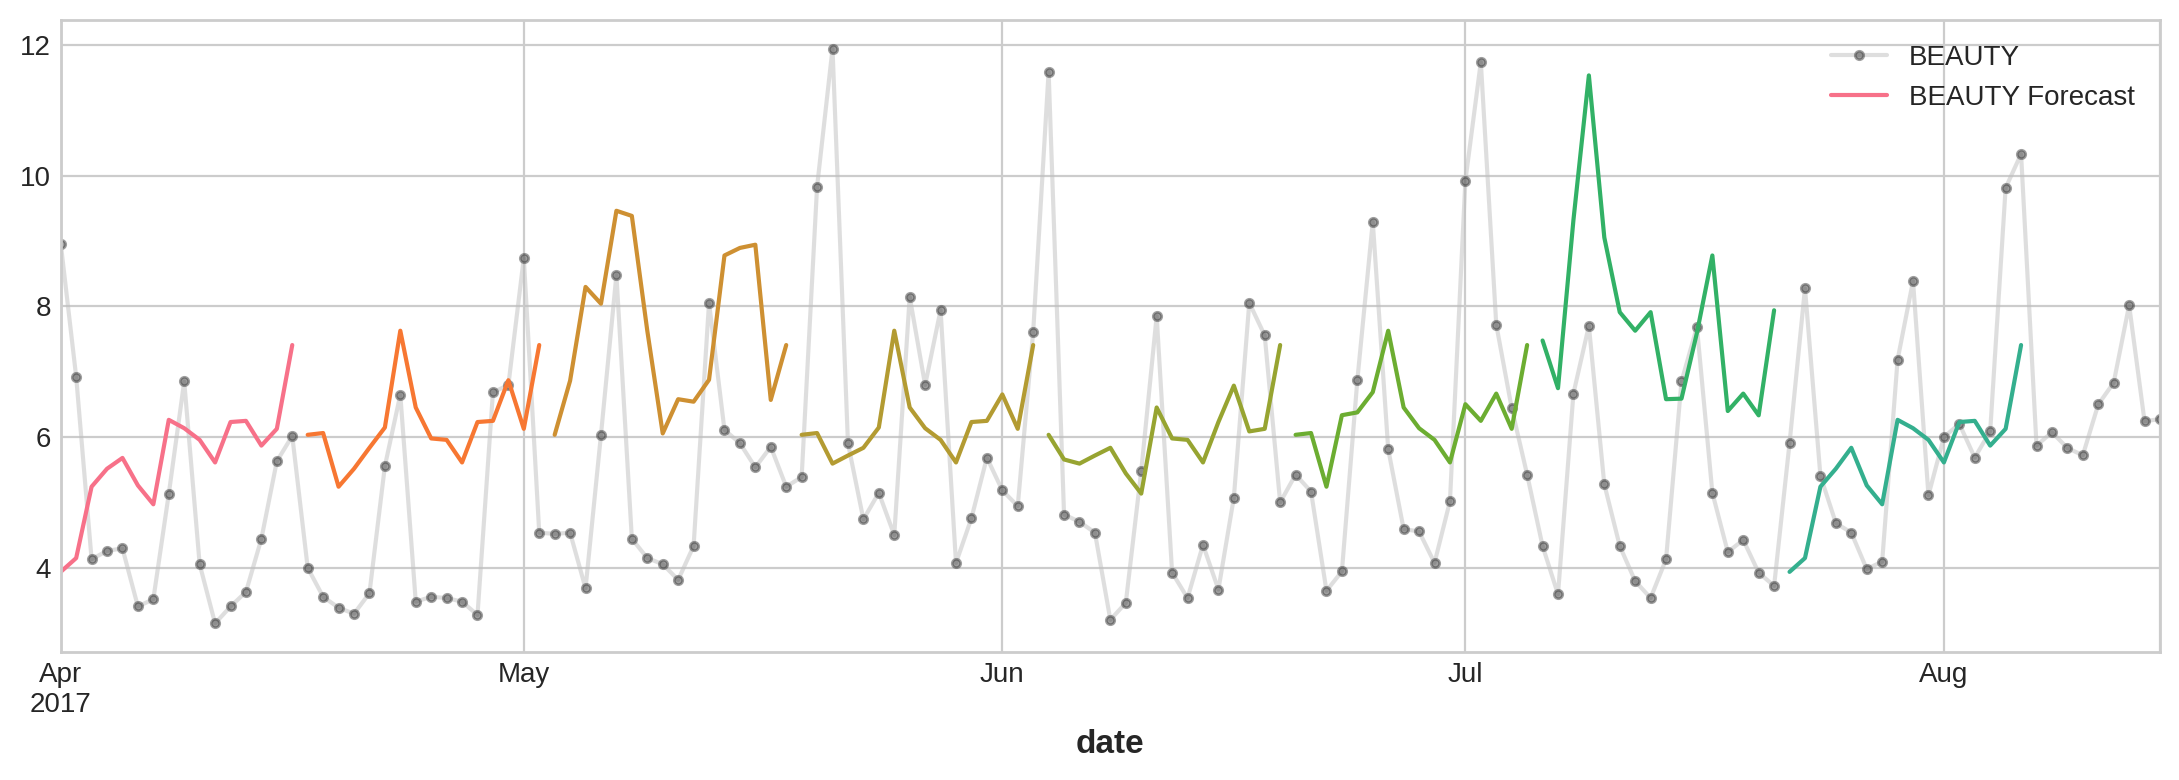

In [12]:
FAMILY = 'BEAUTY'
START = '2017-04-01'
EVERY = 16

y_pred_ = y_pred.xs(FAMILY, level='family', axis=0).loc[START:]
y_ = family_sales.loc[START:, 'sales'].loc[:, FAMILY]

fig, ax = plt.subplots(1, 1, figsize=(11, 4))
ax = y_.plot(**plot_params, ax=ax, alpha=0.5)
ax = plot_multistep(y_pred_, ax=ax, every=EVERY)
_ = ax.legend([FAMILY, FAMILY + ' Forecast'])